# SP-004 — Pair-Block Packing

Notebook de investigación y experimento. No integra M4 al motor productivo. Ejecuta las políticas en secuencia con el motor y las métricas de NewGlass. Los outputs incluidos provienen de la corrida local guardada; Andro puede repetir las celdas en Google Colab con el repositorio disponible.

## 2. Candidatos evaluados antes

Filler se descartó como opción principal porque FF real ya ordena por área y sus resultados coincidieron prácticamente en TA-027. DJD-1/3 eligió grupos diferentes en parte de su traza, pero tuvo costo alto y no cambió métricas oficiales. Se conservan los documentos, notebooks y resultados anteriores.

## 3. Artículo y adaptación

Cai et al. (2023) generan bloques con dos o más piezas de formas complementarias para mejorar la utilización local. El algoritmo publicado también usa espacios residuales con líneas de referencia, puntuación de asignación, operadores de ajuste/movimiento/llenado/reemplazo/intercambio y estrategias de repacking. Este laboratorio limita la idea a pares y no afirma replicar el método completo. [DOI 10.1016/j.cor.2023.106398](https://doi.org/10.1016/j.cor.2023.106398) · [Ficha editorial](https://www.sciencedirect.com/science/article/pii/S0305054823002629).

## 4. Explicación sencilla y diferencias

Pair-Block busca dos geometrías compatibles que se complementen y las usa como unidad temporal de packing. Dos triángulos opuestos pueden ocupar juntos una caja casi rectangular; cada triángulo conserva su identidad y placement por separado. FF procesa una pieza y toma la primera ubicación; BF y WF comparan el espacio raster que queda para esa pieza. BRF evalúa el espacio residual de una colocación. No encontramos BRF implementado en el backend. Pair-Block evalúa la complementariedad de las propias geometrías antes del packing.

## Sección 5. Entorno reproducible

### Qué hace esta celda

Prepara imports y rutas de trabajo.

### Por qué la necesitamos

Reutilizamos clases geométricas, métricas y optimizadores del repositorio.

### Qué deberíamos observar

Debe aparecer la raíz y la lista SMALL/MEDIUM/COMPLEX.

In [1]:
from pathlib import Path  # Importamos Path para resolver rutas en local y Colab.
import sys  # Importamos sys para habilitar imports del backend.
import csv  # Leemos resultados sin depender de pandas.
import json  # Leemos trazas crudas en JSON.
import gc  # Liberamos memoria entre corridas secuenciales.
repo_root = Path.cwd()  # Tomamos el directorio actual como raíz candidata.
if not (repo_root / "experiments/optimization/loader.py").exists():  # Detectamos si Colab abrió desde otra carpeta.
    repo_root = Path("/content/NewGlass")  # Usamos la ruta habitual del clon en Colab.
if not (repo_root / "experiments/optimization/loader.py").exists():  # Validamos que el repositorio esté disponible.
    raise RuntimeError("Abre desde la raíz de NewGlass o clona en /content/NewGlass.")  # Damos una instrucción accionable.
sys.path.insert(0, str(repo_root / "backend"))  # Habilitamos imports de la capa de dominio.
sys.path.insert(0, str(repo_root))  # Habilitamos imports del laboratorio experimental.
from app.modules.optimization.domain.first_fit import FirstFitOptimizer  # Importamos FF actual.
from app.modules.optimization.domain.best_fit import BestFitOptimizer  # Importamos BF actual.
from app.modules.optimization.domain.worst_fit import WorstFitOptimizer  # Importamos WF actual.
from experiments.optimization.block_packing import BlockPackingExperimental  # Importamos Pair-Block aislado.
from experiments.optimization.block_packing.run_benchmark import run_one  # Reutilizamos el ejecutor con métricas NewGlass.
from experiments.optimization.loader import CASES, load_problem, read_case  # Reutilizamos el loader y fixtures congelados.
benchmark_rows = {}  # Guardamos filas y placements para compararlos después.
optimizer_by_method = {"FF": FirstFitOptimizer, "BF": BestFitOptimizer, "WF": WorstFitOptimizer, "Pair-Block": BlockPackingExperimental}  # Asociamos cada etiqueta con su clase.
print("Repositorio:", repo_root)  # Confirmamos qué copia del repo se usa.
print("Ejecución: secuencial; casos oficiales:", CASES)  # Confirmamos orden y ausencia de paralelismo.

Repositorio: C:\Users\patri\GitHub\optimizador-vidrio
Ejecución: secuencial; casos oficiales: ('EXP-SMALL-001', 'EXP-MEDIUM-001', 'EXP-COMPLEX-001')


### Interpretación de la salida

Pair-Block se importa desde experiments/; FF/BF/WF siguen siendo el código actual.

## Sección 6. Entradas y fixtures

### Qué hace esta celda

Carga TA-027 y el caso discriminante aparte.

### Por qué la necesitamos

La comparación usa las entradas reales y mantiene intacta la matriz oficial.

### Qué deberíamos observar

Los casos oficiales deben contener 3, 9 y 24 unidades.

In [2]:
for case_id in CASES:  # Recorremos los fixtures oficiales en el orden congelado.
    case_data = read_case(case_id)  # Leemos el JSON sin modificarlo.
    problem = load_problem(case_id)  # Creamos snapshots independientes para el motor.
    print(case_id, "unidades:", len(problem.units), "grupos:", len(problem.groups), "fuentes:", len(case_data["stock"]))  # Resumimos entrada y compatibilidades.
block_data = json.loads((repo_root / "experiments/optimization/block_packing/cases/BLOCK-DISCRIMINANT-001.json").read_text(encoding="utf-8"))  # Cargamos aparte la demo no oficial.
print(block_data["label"], "piezas:", sum(item["cantidad"] for item in block_data["pieces"]))  # Separamos la demo de TA-027.

EXP-SMALL-001 unidades: 3 grupos: 1 fuentes: 2
EXP-MEDIUM-001 unidades: 9 grupos: 1 fuentes: 3
EXP-COMPLEX-001 unidades: 24 grupos: 2 fuentes: 5
DEMO DIDÁCTICA — NO PERTENECE AL BENCHMARK OFICIAL piezas: 3


### Interpretación de la salida

El caso adicional prueba composición y trazabilidad; sus métricas no se mezclan con los resultados TA-027.

## Sección 7. Criterio raster de complementariedad

### Qué hace esta celda

Explica cómo se determina si una pareja mejora la utilización local.

### Por qué la necesitamos

Los pasajes editoriales accesibles respaldan el objetivo de complementariedad, pero no una fórmula autónoma universal.

### Qué deberíamos observar

La adaptación calcula celdas ocupadas entre celdas de la caja envolvente y exige superar la densidad raster individual mayor.

## Sección 8. Filtros para mantener acotado el costo

### Qué hace esta celda

Muestra cuántos pares pasan los filtros y la evaluación geométrica.

### Por qué la necesitamos

Se empieza con parejas, límites de geometría y memoria para un equipo de 8 GB.

### Qué deberíamos observar

El filtro de escala es 4:1; se prueban hasta ocho alineaciones por eje y solo rotaciones cardinales permitidas.

In [3]:
trace_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_block_trace.json"  # Ubicamos la traza del benchmark local.
trace_data = json.loads(trace_path.read_text(encoding="utf-8"))  # Cargamos los contadores reales.
for entry in trace_data["results"]:  # Recorremos casos y políticas.
    if entry["method"] == "Pair-Block":  # Seleccionamos filas con datos propios de bloques.
        item = entry["block_trace"]  # Obtenemos los contadores de pares.
        print(entry["case"], item["candidate_pairs"], item["filtered_pairs"], item["geometrically_checked_pairs"], item["accepted_blocks"])  # Mostramos candidatos, filtros, chequeos y bloques.

EXP-SMALL-001 3 0 3 0
EXP-MEDIUM-001 36 0 36 0
EXP-COMPLEX-001 181 0 181 1
BLOCK-DISCRIMINANT-001 3 0 3 1


### Interpretación de la salida

COMPLEX evaluó 181 pares compatibles y aceptó una composición; no logró colocarla como bloque y usó el fallback individual. El discriminante sí colocó un bloque.

## Sección 9. Rotaciones y separación

### Qué hace esta celda

Resume cómo se restringen las orientaciones y se valida la distancia entre piezas.

### Por qué la necesitamos

Cada miembro debe cumplir el contrato geométrico vigente de NewGlass.

### Qué deberíamos observar

Se espera el subconjunto cardinal permitido por el paso angular de 5 grados.

In [4]:
small_config = read_case("EXP-SMALL-001")["config"]  # Leemos el paso angular oficial.
allowed_angles = [angle for angle in (0, 90, 180, 270) if angle % small_config["angular_step_deg"] == 0]  # Filtramos a los giros cardinales permitidos.
print("paso angular:", small_config["angular_step_deg"], "orientaciones:", allowed_angles)  # Informamos el subconjunto evaluado.

paso angular: 5 orientaciones: [0, 90, 180, 270]


### Interpretación de la salida

La separación interna usa SheetLayout y su regla raster del motor; no se crean rotaciones nuevas.

## Sección 10. Demo gráfica de dos triángulos

### Qué hace esta celda

Muestra piezas independientes, bloque temporal y colocación en una fuente.

### Por qué la necesitamos

La caja compuesta nunca reemplaza los dos placements originales.

### Qué deberíamos observar

La figura está rotulada como conceptual y ajena al benchmark oficial.

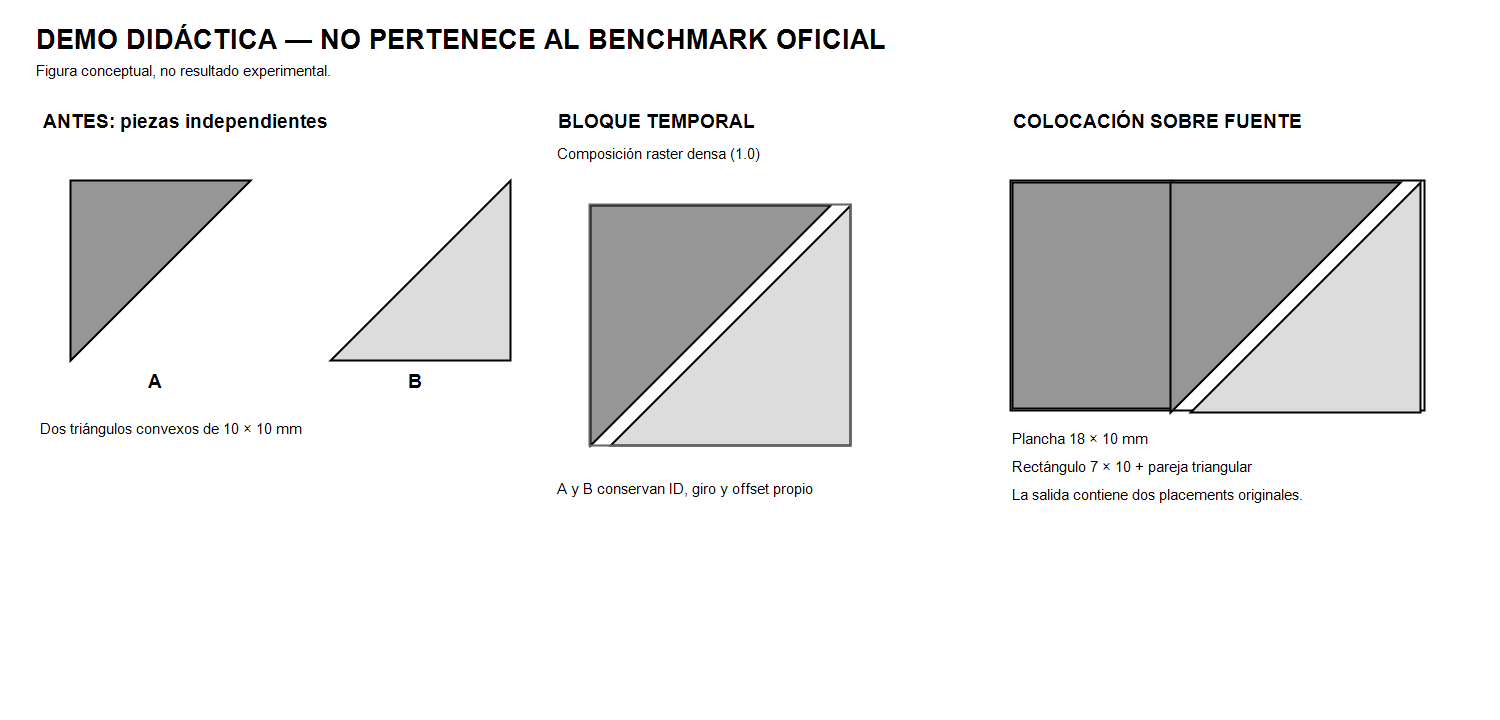

In [5]:
from IPython.display import Image, display  # Importamos el visor de imágenes de Jupyter/Colab.
demo_path = repo_root / "experiments/optimization/block_packing/figures/block-packing-demo.png"  # Localizamos la ilustración en grises.
display(Image(filename=str(demo_path)))  # Mostramos los tres estados de la composición.

### Interpretación de la salida

La pareja demostrativa alcanza compactación raster 1.0 y conserva IDs, giros y offsets propios.

## Sección 11. EXP-SMALL-001 — FF

### Qué hace esta celda

Ejecuta FF sobre EXP-SMALL-001.

### Por qué la necesitamos

Tres rectángulos iguales comprueban que no se fuercen bloques sin ganancia local.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [6]:
case_id = "EXP-SMALL-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "FF"  # Elegimos el método que corre en esta celda.
optimizer_class = FirstFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-SMALL-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-SMALL-001 FF: 3/3; uso=60.000%; merma=0.00 mm²; retazos=1; planchas=1; runtime=29.328 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 12. EXP-SMALL-001 — BF

### Qué hace esta celda

Ejecuta BF sobre EXP-SMALL-001.

### Por qué la necesitamos

Tres rectángulos iguales comprueban que no se fuercen bloques sin ganancia local.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [7]:
case_id = "EXP-SMALL-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "BF"  # Elegimos el método que corre en esta celda.
optimizer_class = BestFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-SMALL-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-SMALL-001 BF: 3/3; uso=60.000%; merma=0.00 mm²; retazos=1; planchas=1; runtime=30.404 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 13. EXP-SMALL-001 — WF

### Qué hace esta celda

Ejecuta WF sobre EXP-SMALL-001.

### Por qué la necesitamos

Tres rectángulos iguales comprueban que no se fuercen bloques sin ganancia local.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [8]:
case_id = "EXP-SMALL-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "WF"  # Elegimos el método que corre en esta celda.
optimizer_class = WorstFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-SMALL-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-SMALL-001 WF: 3/3; uso=60.000%; merma=0.00 mm²; retazos=1; planchas=1; runtime=21.273 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 14. EXP-SMALL-001 — Pair-Block

### Qué hace esta celda

Ejecuta Pair-Block sobre EXP-SMALL-001.

### Por qué la necesitamos

Tres rectángulos iguales comprueban que no se fuercen bloques sin ganancia local.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [9]:
case_id = "EXP-SMALL-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "Pair-Block"  # Elegimos el método que corre en esta celda.
optimizer_class = BlockPackingExperimental  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-SMALL-001 Pair-Block: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.
print("bloques colocados:", row["placed_blocks"], "compactación:", row["block_compaction"])  # Añadimos las métricas específicas Pair-Block.

EXP-SMALL-001 Pair-Block: 3/3; uso=60.000%; merma=0.00 mm²; retazos=1; planchas=1; runtime=23.806 ms
bloques colocados: 0 compactación: 0.000000


### Interpretación de la salida

Los cuatro métodos colocaron 3/3 unidades, usaron un retazo y una plancha, y lograron 60%. Pair-Block no formó pareja útil.

## Sección 15. EXP-MEDIUM-001 — FF

### Qué hace esta celda

Ejecuta FF sobre EXP-MEDIUM-001.

### Por qué la necesitamos

Nueve rectángulos y círculos comprueban cobertura y fallback a piezas individuales.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [10]:
case_id = "EXP-MEDIUM-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "FF"  # Elegimos el método que corre en esta celda.
optimizer_class = FirstFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-MEDIUM-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-MEDIUM-001 FF: 9/9; uso=28.413%; merma=201.86 mm²; retazos=2; planchas=1; runtime=33.827 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 16. EXP-MEDIUM-001 — BF

### Qué hace esta celda

Ejecuta BF sobre EXP-MEDIUM-001.

### Por qué la necesitamos

Nueve rectángulos y círculos comprueban cobertura y fallback a piezas individuales.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [11]:
case_id = "EXP-MEDIUM-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "BF"  # Elegimos el método que corre en esta celda.
optimizer_class = BestFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-MEDIUM-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-MEDIUM-001 BF: 9/9; uso=28.413%; merma=193.86 mm²; retazos=2; planchas=1; runtime=46.531 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 17. EXP-MEDIUM-001 — WF

### Qué hace esta celda

Ejecuta WF sobre EXP-MEDIUM-001.

### Por qué la necesitamos

Nueve rectángulos y círculos comprueban cobertura y fallback a piezas individuales.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [12]:
case_id = "EXP-MEDIUM-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "WF"  # Elegimos el método que corre en esta celda.
optimizer_class = WorstFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-MEDIUM-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-MEDIUM-001 WF: 9/9; uso=18.584%; merma=301.86 mm²; retazos=2; planchas=2; runtime=30.976 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 18. EXP-MEDIUM-001 — Pair-Block

### Qué hace esta celda

Ejecuta Pair-Block sobre EXP-MEDIUM-001.

### Por qué la necesitamos

Nueve rectángulos y círculos comprueban cobertura y fallback a piezas individuales.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [13]:
case_id = "EXP-MEDIUM-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "Pair-Block"  # Elegimos el método que corre en esta celda.
optimizer_class = BlockPackingExperimental  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-MEDIUM-001 Pair-Block: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.
print("bloques colocados:", row["placed_blocks"], "compactación:", row["block_compaction"])  # Añadimos las métricas específicas Pair-Block.

EXP-MEDIUM-001 Pair-Block: 9/9; uso=28.413%; merma=201.86 mm²; retazos=2; planchas=1; runtime=306.361 ms
bloques colocados: 0 compactación: 0.000000


### Interpretación de la salida

Pair-Block igualó FF en métricas y colocación total: 9/9, dos retazos y una plancha. No formó bloques.

## Sección 19. EXP-COMPLEX-001 — FF

### Qué hace esta celda

Ejecuta FF sobre EXP-COMPLEX-001.

### Por qué la necesitamos

Veinticuatro piezas en cinco grupos exponen el costo de evaluar pares y fallback cuando el bloque no cabe.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [14]:
case_id = "EXP-COMPLEX-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "FF"  # Elegimos el método que corre en esta celda.
optimizer_class = FirstFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-COMPLEX-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-COMPLEX-001 FF: 24/24; uso=29.598%; merma=746.72 mm²; retazos=3; planchas=3; runtime=167.150 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 20. EXP-COMPLEX-001 — BF

### Qué hace esta celda

Ejecuta BF sobre EXP-COMPLEX-001.

### Por qué la necesitamos

Veinticuatro piezas en cinco grupos exponen el costo de evaluar pares y fallback cuando el bloque no cabe.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [15]:
case_id = "EXP-COMPLEX-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "BF"  # Elegimos el método que corre en esta celda.
optimizer_class = BestFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-COMPLEX-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-COMPLEX-001 BF: 24/24; uso=29.598%; merma=746.72 mm²; retazos=3; planchas=3; runtime=174.167 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 21. EXP-COMPLEX-001 — WF

### Qué hace esta celda

Ejecuta WF sobre EXP-COMPLEX-001.

### Por qué la necesitamos

Veinticuatro piezas en cinco grupos exponen el costo de evaluar pares y fallback cuando el bloque no cabe.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [16]:
case_id = "EXP-COMPLEX-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "WF"  # Elegimos el método que corre en esta celda.
optimizer_class = WorstFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-COMPLEX-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

EXP-COMPLEX-001 WF: 24/24; uso=25.309%; merma=886.72 mm²; retazos=3; planchas=4; runtime=160.632 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 22. EXP-COMPLEX-001 — Pair-Block

### Qué hace esta celda

Ejecuta Pair-Block sobre EXP-COMPLEX-001.

### Por qué la necesitamos

Veinticuatro piezas en cinco grupos exponen el costo de evaluar pares y fallback cuando el bloque no cabe.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [17]:
case_id = "EXP-COMPLEX-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "Pair-Block"  # Elegimos el método que corre en esta celda.
optimizer_class = BlockPackingExperimental  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"EXP-COMPLEX-001 Pair-Block: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.
print("bloques colocados:", row["placed_blocks"], "compactación:", row["block_compaction"])  # Añadimos las métricas específicas Pair-Block.

EXP-COMPLEX-001 Pair-Block: 24/24; uso=29.598%; merma=746.72 mm²; retazos=3; planchas=3; runtime=3047.899 ms
bloques colocados: 0 compactación: 0.000000


### Interpretación de la salida

Pair-Block colocó 24/24 y propuso un par de compactación 0.778, pero no cupo como bloque y pasó al fallback individual. Igualó FF en fuentes, aprovechamiento y merma; tomó unos 3.00 s frente a 0.17 s de FF.

## Sección 23. BLOCK-DISCRIMINANT-001 — FF

### Qué hace esta celda

Ejecuta FF sobre BLOCK-DISCRIMINANT-001.

### Por qué la necesitamos

La demo prueba un bloque real de triángulos y conserva los placements por pieza.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [18]:
case_id = "BLOCK-DISCRIMINANT-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "FF"  # Elegimos el método que corre en esta celda.
optimizer_class = FirstFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"BLOCK-DISCRIMINANT-001 FF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

BLOCK-DISCRIMINANT-001 FF: 3/3; uso=94.444%; merma=10.00 mm²; retazos=0; planchas=1; runtime=18.005 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 24. BLOCK-DISCRIMINANT-001 — BF

### Qué hace esta celda

Ejecuta BF sobre BLOCK-DISCRIMINANT-001.

### Por qué la necesitamos

La demo prueba un bloque real de triángulos y conserva los placements por pieza.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [19]:
case_id = "BLOCK-DISCRIMINANT-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "BF"  # Elegimos el método que corre en esta celda.
optimizer_class = BestFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"BLOCK-DISCRIMINANT-001 BF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

BLOCK-DISCRIMINANT-001 BF: 3/3; uso=94.444%; merma=10.00 mm²; retazos=0; planchas=1; runtime=14.083 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 25. BLOCK-DISCRIMINANT-001 — WF

### Qué hace esta celda

Ejecuta WF sobre BLOCK-DISCRIMINANT-001.

### Por qué la necesitamos

La demo prueba un bloque real de triángulos y conserva los placements por pieza.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [20]:
case_id = "BLOCK-DISCRIMINANT-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "WF"  # Elegimos el método que corre en esta celda.
optimizer_class = WorstFitOptimizer  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"BLOCK-DISCRIMINANT-001 WF: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.

BLOCK-DISCRIMINANT-001 WF: 3/3; uso=94.444%; merma=10.00 mm²; retazos=0; planchas=1; runtime=13.967 ms


### Interpretación de la salida

La fila es referencia con la misma entrada y configuración.

## Sección 26. BLOCK-DISCRIMINANT-001 — Pair-Block

### Qué hace esta celda

Ejecuta Pair-Block sobre BLOCK-DISCRIMINANT-001.

### Por qué la necesitamos

La demo prueba un bloque real de triángulos y conserva los placements por pieza.

### Qué deberíamos observar

Se registran las métricas funcionales y, en Pair-Block, los contadores propios.

In [21]:
case_id = "BLOCK-DISCRIMINANT-001"  # Seleccionamos una instancia fija de la matriz.
method_name = "Pair-Block"  # Elegimos el método que corre en esta celda.
optimizer_class = BlockPackingExperimental  # Reutilizamos el optimizador real o el laboratorio aislado.
row, detail = run_one(case_id, method_name, optimizer_class)  # Ejecutamos packing y métricas NewGlass.
benchmark_rows[(case_id, method_name)] = (row, detail)  # Guardamos métricas y placements para comparar.
print(f"BLOCK-DISCRIMINANT-001 Pair-Block: {row['placed_units']}/{row['requested_units']}; uso={row['utilization_pct']}%; merma={row['waste']} mm²; retazos={row['remnants_used']}; planchas={row['sheets_used']}; runtime={row['runtime_ms']} ms")  # Mostramos la medición.
print("bloques colocados:", row["placed_blocks"], "compactación:", row["block_compaction"])  # Añadimos las métricas específicas Pair-Block.

BLOCK-DISCRIMINANT-001 Pair-Block: 3/3; uso=94.444%; merma=10.00 mm²; retazos=0; planchas=1; runtime=107.011 ms
bloques colocados: 1 compactación: 1.000000


### Interpretación de la salida

Pair-Block colocó un bloque con triángulos en 0°/180°, preservó sus IDs y mantuvo 3/3. Las métricas globales empataron con FF/BF/WF.

## Sección 27. Tabla consolidada

### Qué hace esta celda

Lee y presenta la evidencia CSV sin transcribir números.

### Por qué la necesitamos

FF/BF/WF/Pair-Block usan el mismo cálculo oficial de métricas.

### Qué deberíamos observar

Hay 16 filas para cuatro casos y cuatro métodos.

In [22]:
csv_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_block_results.csv"  # Abrimos el CSV real del benchmark.
with csv_path.open(encoding="utf-8", newline="") as file:  # Leemos filas UTF-8 sin alterar columnas.
    consolidated = list(csv.DictReader(file))  # Convertimos las filas en diccionarios.
print("caso | método | puestas | retazos | planchas | uso % | merma mm² | recuperable mm² | ms")  # Imprimimos el encabezado.
for item in consolidated:  # Recorremos las 16 combinaciones de caso y método.
    print(item["case"], item["method"], item["placed_units"], item["remnants_used"], item["sheets_used"], item["utilization_pct"], item["waste"], item["recoverable_area"], item["runtime_ms"], sep=" | ")  # Mostramos métricas comparables.

caso | método | puestas | retazos | planchas | uso % | merma mm² | recuperable mm² | ms
EXP-SMALL-001 | FF | 3 | 1 | 1 | 60.000 | 0.00 | 8 | 20.095
EXP-SMALL-001 | BF | 3 | 1 | 1 | 60.000 | 0.00 | 8 | 20.207
EXP-SMALL-001 | WF | 3 | 1 | 1 | 60.000 | 0.00 | 8 | 19.458
EXP-SMALL-001 | Pair-Block | 3 | 1 | 1 | 60.000 | 0.00 | 8 | 23.220
EXP-MEDIUM-001 | FF | 9 | 2 | 1 | 28.413 | 201.86 | 58 | 31.954
EXP-MEDIUM-001 | BF | 9 | 2 | 1 | 28.413 | 193.86 | 66 | 47.703
EXP-MEDIUM-001 | WF | 9 | 2 | 2 | 18.584 | 301.86 | 150 | 30.278
EXP-MEDIUM-001 | Pair-Block | 9 | 2 | 1 | 28.413 | 201.86 | 58 | 291.847
EXP-COMPLEX-001 | FF | 24 | 3 | 3 | 29.598 | 746.72 | 184 | 169.095
EXP-COMPLEX-001 | BF | 24 | 3 | 3 | 29.598 | 746.72 | 184 | 166.715
EXP-COMPLEX-001 | WF | 24 | 3 | 4 | 25.309 | 886.72 | 268 | 161.658
EXP-COMPLEX-001 | Pair-Block | 24 | 3 | 3 | 29.598 | 746.72 | 184 | 2998.492
BLOCK-DISCRIMINANT-001 | FF | 3 | 0 | 1 | 94.444 | 10.00 | 0 | 14.831
BLOCK-DISCRIMINANT-001 | BF | 3 | 0 | 1 | 94.44

### Interpretación de la salida

El discriminante prueba formación, mientras la decisión se apoya en TA-027. Pair-Block empata con FF en los tres fixtures; BF reduce 8 mm² de merma en MEDIUM.

## Sección 28. Bloques seleccionados y placements originales

### Qué hace esta celda

Muestra IDs, rotaciones, offsets internos y fuente de cada bloque.

### Por qué la necesitamos

La trazabilidad de piezas debe sobrevivir a la colocación como máscara compuesta.

### Qué deberíamos observar

Solo COMPLEX y el discriminante contienen un bloque seleccionado.

In [23]:
trace_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_block_trace.json"  # Localizamos la traza de placements.
trace_data = json.loads(trace_path.read_text(encoding="utf-8"))  # Leemos giros, offsets e identidades.
for entry in trace_data["results"]:  # Recorremos todos los casos y métodos.
    if entry["method"] == "Pair-Block":  # Nos quedamos con bloques y fallback.
        print(entry["case"], entry["block_trace"]["selected_blocks"])  # Mostramos composición y ubicación.

EXP-SMALL-001 []
EXP-MEDIUM-001 []
EXP-COMPLEX-001 [{'piece_identities': [[6, 1], [6, 2]], 'rotations_deg': ['0', '180'], 'offsets_cells': [[0, 0], [4, 0]], 'compactness': 0.777778, 'placed': False}]
BLOCK-DISCRIMINANT-001 [{'piece_identities': [[2, 1], [3, 1]], 'rotations_deg': ['0', '180'], 'offsets_cells': [[0, 0], [1, 0]], 'compactness': 1.0, 'placed': True, 'source': 'PLANCHA', 'material_id': 990, 'block_x_mm': '0', 'block_y_mm': '0'}]


### Interpretación de la salida

En COMPLEX se aceptó geométricamente un par pero no cupo como bloque, así que pasó al fallback individual. En el discriminante los triángulos sí se colocaron como bloque con giros 0°/180° y un offset de una celda.

## Sección 29. Determinismo ×3

### Qué hace esta celda

Compara layouts, pares, giros y métricas funcionales de tres corridas.

### Por qué la necesitamos

El reloj puede variar, pero las decisiones geométricas deben permanecer iguales.

### Qué deberíamos observar

Los cuatro casos deben registrar PASS.

In [24]:
det_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_block_trace.json"  # Abrimos el resumen de repeticiones.
determinism = json.loads(det_path.read_text(encoding="utf-8"))["determinism"]  # Separamos estados de determinismo.
for case_id, status in determinism.items():  # Recorremos SMALL, MEDIUM, COMPLEX y la demo.
    print(case_id, status["runs"], "PASS" if status["pass"] else "FAIL", status["runtime_ms"])  # Reportamos firma y tiempos.

EXP-SMALL-001 3 PASS ['25.337', '117.175', '24.430']
EXP-MEDIUM-001 3 PASS ['286.885', '293.925', '292.365']
EXP-COMPLEX-001 3 PASS ['2607.316', '1963.945', '1842.398']
BLOCK-DISCRIMINANT-001 3 PASS ['86.314', '72.198', '64.879']


### Interpretación de la salida

Los placements y bloques coincidieron en las tres ejecuciones de cada caso; solo cambian los tiempos.

## Sección 30. Diagnóstico adicional DJD

### Qué hace esta celda

Lee cuatro casos externos con la intención fijada antes de las corridas.

### Por qué la necesitamos

La matriz comprueba grupos y métricas, no representa una muestra estadística.

### Qué deberíamos observar

Se espera categoría A/B/C/D, tamaño de grupos y runtime.

In [25]:
diagnostic_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_djd_diagnostic_results.csv"  # Abrimos el CSV DJD no oficial.
with diagnostic_path.open(encoding="utf-8", newline="") as file:  # Leemos las comparaciones completas.
    diagnostic_rows = list(csv.DictReader(file))  # Guardamos FF/BF/WF/DJD.
classification_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_djd_diagnostic_trace.json"  # Localizamos grupos y categorías.
classification = json.loads(classification_path.read_text(encoding="utf-8"))  # Leemos la clasificación previa.
for case_id, item in classification["classifications"].items():  # Recorremos los cuatro casos fijados.
    row = next(value for value in diagnostic_rows if value["case"] == case_id and value["method"] == "DJD-1/3")  # Encontramos sus métricas oficiales.
    print(case_id, item["category"], "grupos:", item["selected_group_sizes"], "colocadas:", row["placed_units"], "planchas:", row["sheets_used"], "uso:", row["utilization_pct"], "merma:", row["waste"], "ms:", row["runtime_ms"])  # Resumimos selección, resultado y costo.

DJD-DIAGNOSTIC-001 A grupos: 1;1;1;1 colocadas: 4 planchas: 1 uso: 58.729 merma: 11.43 ms: 3.266
DJD-DIAGNOSTIC-002 A grupos: 1;1 colocadas: 2 planchas: 1 uso: 50.000 merma: 48.00 ms: 23.969
DJD-DIAGNOSTIC-003 A grupos: 1;3 colocadas: 4 planchas: 1 uso: 100.000 merma: 0.00 ms: 2.275
DJD-DIAGNOSTIC-004 A grupos: 1;1;1;1 colocadas: 4 planchas: 1 uso: 65.570 merma: 6.43 ms: 5.578


### Interpretación de la salida

El caso 003 eligió una terna con métricas iguales. El caso 004 igualó al mejor baseline y se diferenció de WF. DJD no superó a FF/BF en estas pruebas.

## Sección 31. Aprovechamiento por método

### Qué hace esta celda

Carga la figura generada a partir de métricas crudas.

### Por qué la necesitamos

El gráfico ayuda a comparar patrones sin sustituir los valores tabulares.

### Qué deberíamos observar

Las cuatro barras por grupo representan FF, BF, WF y Pair-Block.

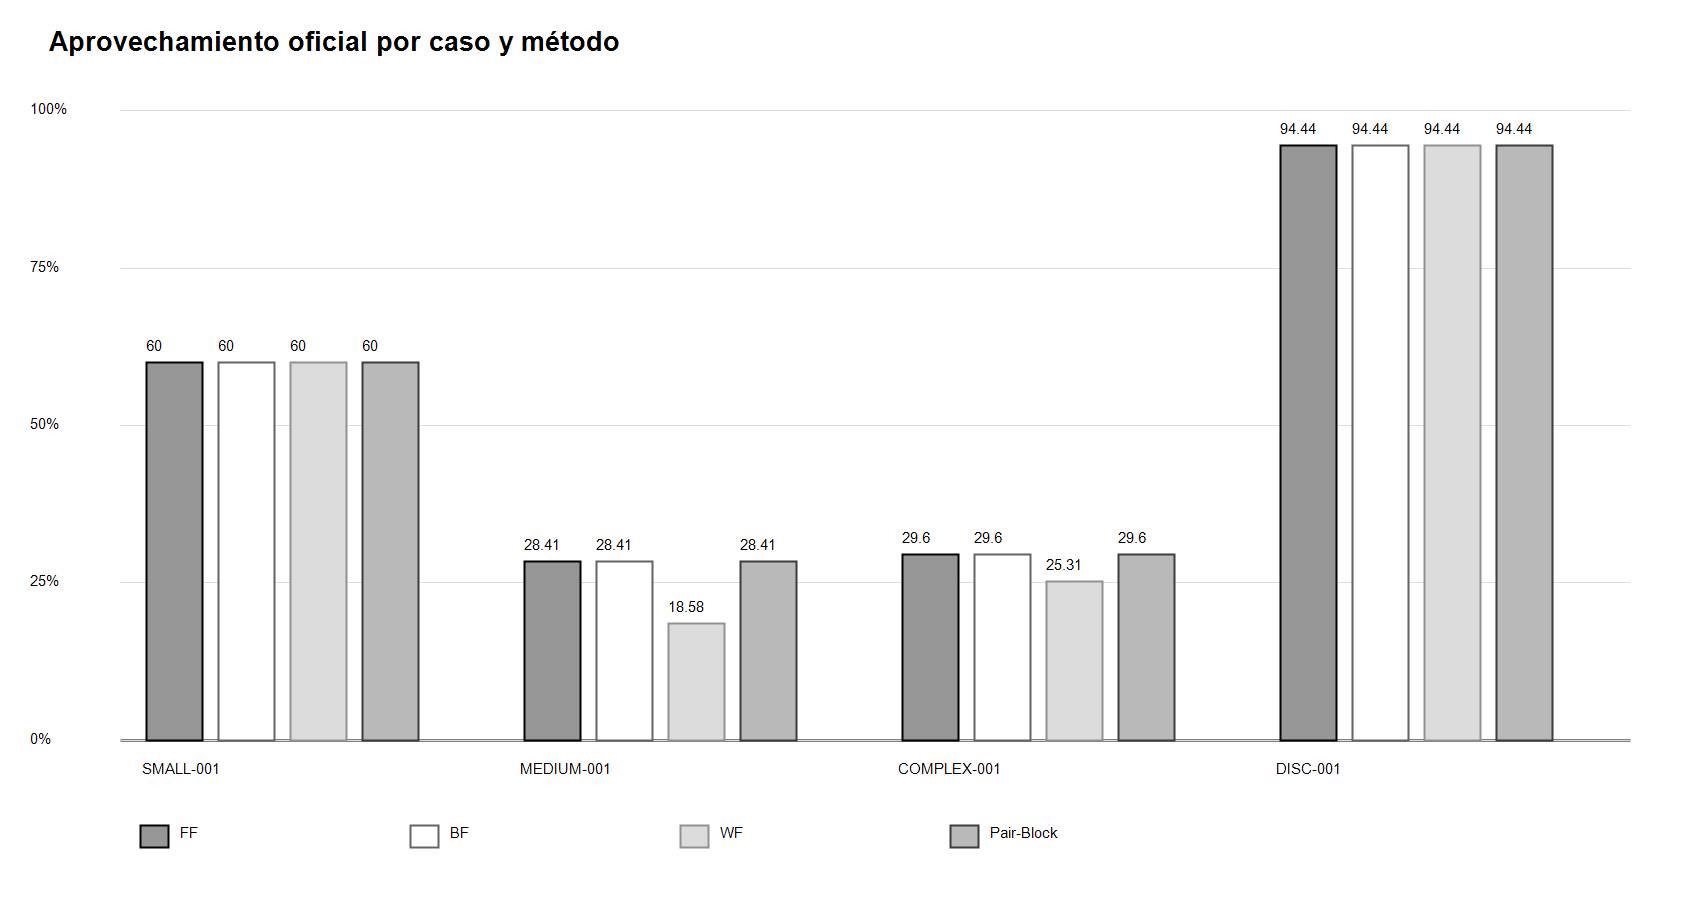

In [26]:
from IPython.display import Image, display  # Importamos el renderizador de Colab.
chart_path = repo_root / "experiments/optimization/block_packing/figures/utilization-by-method.png"  # Localizamos el gráfico en el repo.
display(Image(filename=str(chart_path)))  # Mostramos el PNG de la corrida real.

### Interpretación de la salida

Pair-Block no cambia aprovechamiento oficial en SMALL/MEDIUM/COMPLEX; todos empatan en el discriminante.

## Sección 32. Fuentes por método

### Qué hace esta celda

Carga la figura generada a partir de métricas crudas.

### Por qué la necesitamos

El gráfico ayuda a comparar patrones sin sustituir los valores tabulares.

### Qué deberíamos observar

Las cuatro barras por grupo representan FF, BF, WF y Pair-Block.

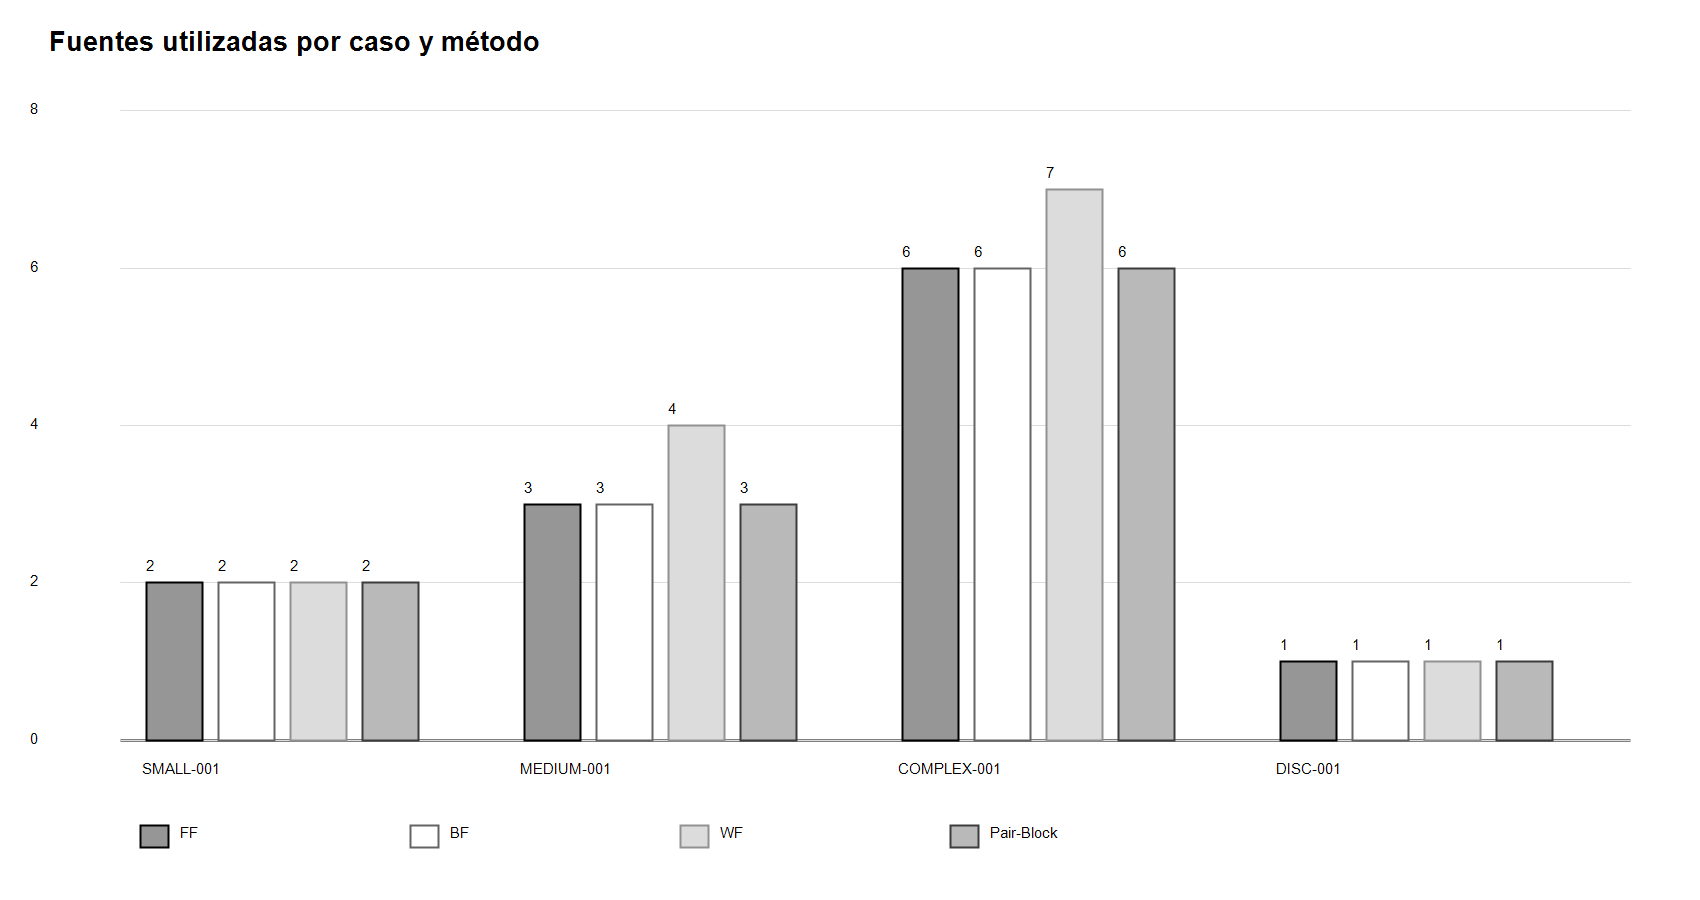

In [27]:
from IPython.display import Image, display  # Importamos el renderizador de Colab.
chart_path = repo_root / "experiments/optimization/block_packing/figures/sources-by-method.png"  # Localizamos el gráfico en el repo.
display(Image(filename=str(chart_path)))  # Mostramos el PNG de la corrida real.

### Interpretación de la salida

WF abrió más planchas en MEDIUM y COMPLEX; Pair-Block coincide con FF/BF en cantidad.

## Sección 33. Tiempo por método

### Qué hace esta celda

Carga la figura generada a partir de métricas crudas.

### Por qué la necesitamos

El gráfico ayuda a comparar patrones sin sustituir los valores tabulares.

### Qué deberíamos observar

Las cuatro barras por grupo representan FF, BF, WF y Pair-Block.

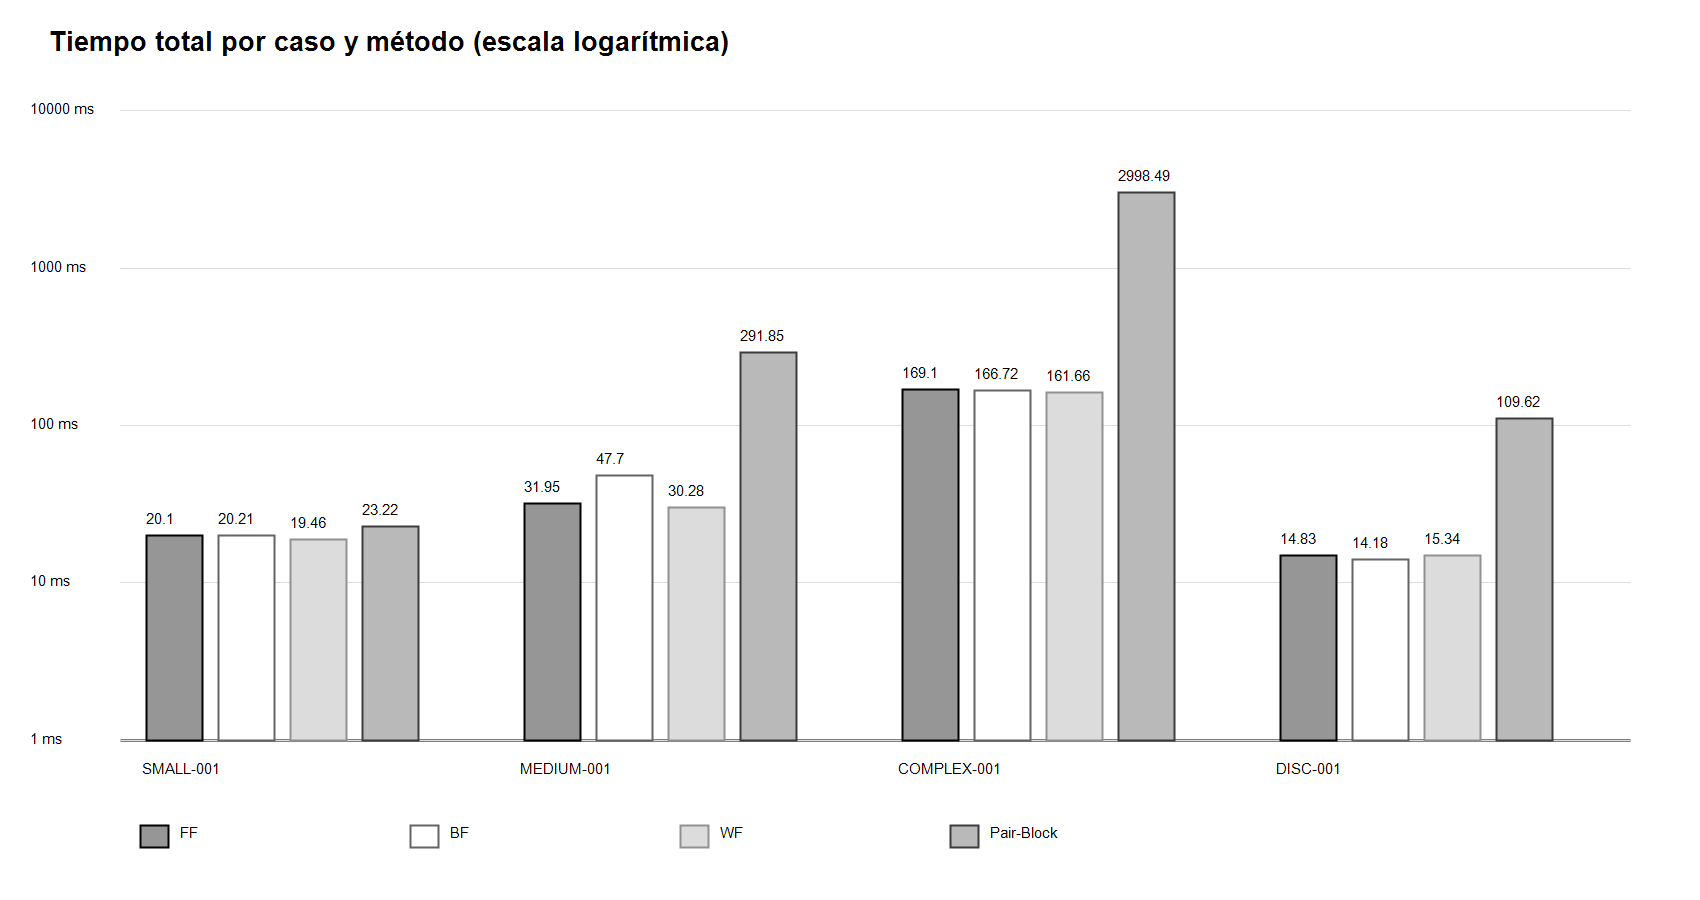

In [28]:
from IPython.display import Image, display  # Importamos el renderizador de Colab.
chart_path = repo_root / "experiments/optimization/block_packing/figures/runtime-by-method.png"  # Localizamos el gráfico en el repo.
display(Image(filename=str(chart_path)))  # Mostramos el PNG de la corrida real.

### Interpretación de la salida

Pair-Block tarda alrededor de 0.29 s en MEDIUM y 3.00 s en COMPLEX; el eje de tiempo es logarítmico.

## Sección 34. Evaluación comparativa y selección de candidato M4

### Qué hace esta celda

Resume resultados y conecta la evidencia de Filler, DJD y Pair-Block.

### Por qué la necesitamos

Una heurística debe aportar diferencia útil a un costo que compense.

### Qué deberíamos observar

Pair-Block demuestra mecanismo y trazabilidad, pero el beneficio oficial es pequeño frente al aumento de runtime.

### Lectura de esta corrida

- **Filler:** sigue descartado como opción principal; sus documentos y resultados anteriores se preservan.
- **DJD-1/3:** el diagnóstico no encontró una mejora de grupo sobre el mejor baseline. Una terna produjo la misma métrica final.
- **Pair-Block:** GO para probar el mecanismo en laboratorio; NO-GO para TA-042 ahora. Ningún bloque se colocó en los fixtures oficiales; en COMPLEX la política igualó a FF y tomó cerca de 17.7 veces más. El discriminante sí colocó un bloque y cambió el patrón, pero empató en métricas.

Recomendación: no integrar ninguno de los tres como M4 productiva con esta evidencia. Pair-Block es la opción más directamente alineada con formas complementarias para una futura investigación, condicionada a reducir el costo de generar pares y demostrar cambios funcionales en más instancias razonables.